# Logistic Regression - Diabetes Prediction

## 1. Data Exploration (EDA)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


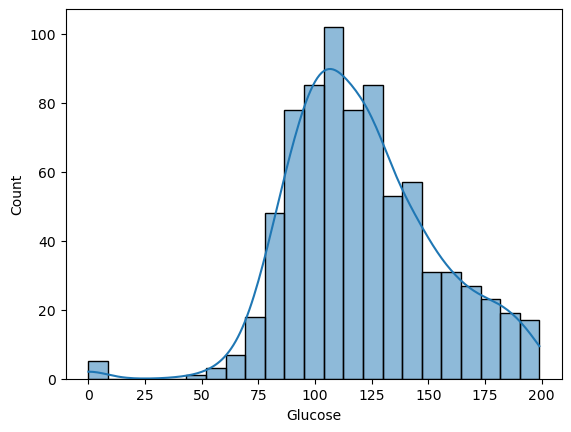

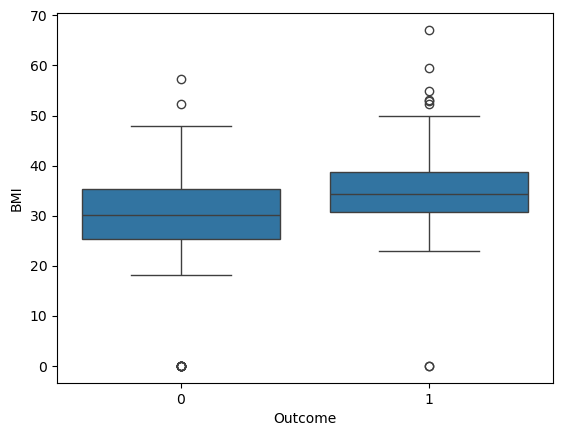

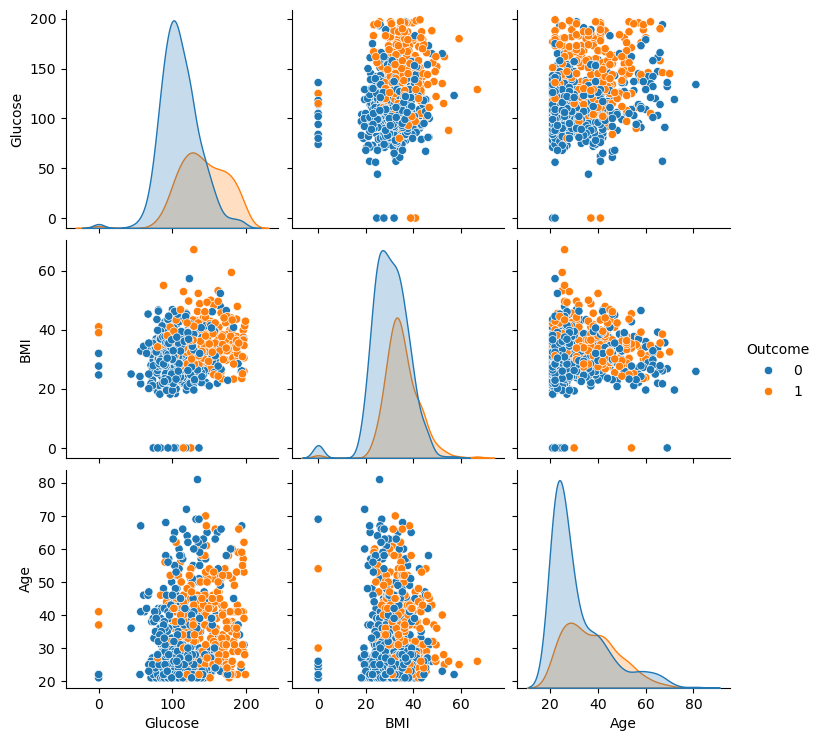

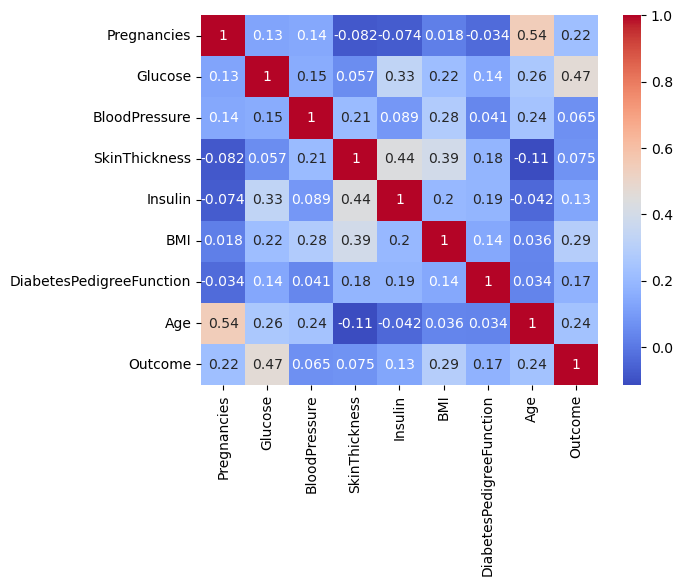

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv("diabetes.csv")

# Basic info
df.info()
df.describe()

# Check missing values
df.isnull().sum()

# Visualizations
sns.histplot(df['Glucose'], kde=True)
plt.show()

sns.boxplot(x='Outcome', y='BMI', data=df)
plt.show()

sns.pairplot(df[['Glucose','BMI','Age','Outcome']], hue='Outcome')
plt.show()

# Correlation heatmap
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
plt.show()


## 2. Data Preprocessing


In [3]:
from sklearn.preprocessing import StandardScaler

# Replace zeros in certain columns with NaN (common in this dataset)
cols_with_zero = ['Glucose','BloodPressure','SkinThickness','Insulin','BMI']
df[cols_with_zero] = df[cols_with_zero].replace(0, np.nan)

# Impute missing values with median
df.fillna(df.median(), inplace=True)

# Features and target
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


## 3. Model Building


In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)


LogisticRegression(max_iter=1000)

## 4. Model Evaluation


Accuracy: 0.7532467532467533
Precision: 0.6666666666666666
Recall: 0.6181818181818182
F1: 0.6415094339622641
ROC-AUC: 0.8229568411386594


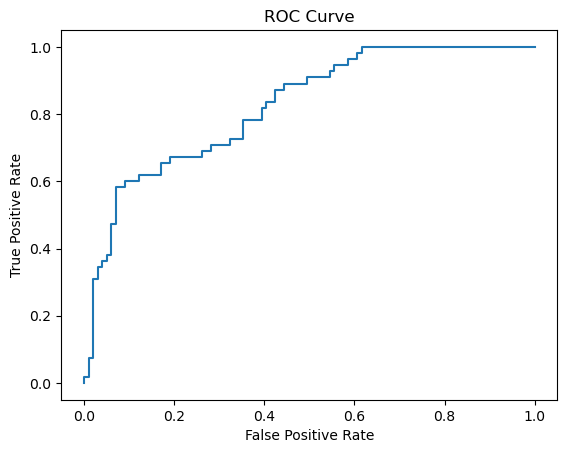

In [5]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:,1]

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1:", f1_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.plot(fpr, tpr)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.show()


## 5. Interpretation


In [6]:
coefficients = pd.DataFrame(model.coef_[0], X.columns, columns=['Coefficient'])
print(coefficients.sort_values(by='Coefficient', ascending=False))


                          Coefficient
Glucose                      1.114496
BMI                          0.683509
Age                          0.401210
Pregnancies                  0.226785
DiabetesPedigreeFunction     0.200471
SkinThickness                0.071687
Insulin                     -0.135922
BloodPressure               -0.151407


Positive coefficients → increase diabetes risk.

Negative coefficients → decrease diabetes risk.

Typically, Glucose, BMI, Age are strong predictors.

## 6. Deployment with Streamlit


In [8]:
# Save model and scaler
import pickle
pickle.dump(model, open("diabetes_model.pkl", "wb"))
pickle.dump(scaler, open("scaler.pkl", "wb"))


Create a separate file app.py:

import streamlit as st
import pickle
import numpy as np

model = pickle.load(open("diabetes_model.pkl", "rb"))
scaler = pickle.load(open("scaler.pkl", "rb"))

st.title("Diabetes Prediction App")

preg = st.number_input("Pregnancies", min_value=0)
glucose = st.number_input("Glucose", min_value=0)
bp = st.number_input("Blood Pressure", min_value=0)
skin = st.number_input("Skin Thickness", min_value=0)
insulin = st.number_input("Insulin", min_value=0)
bmi = st.number_input("BMI", min_value=0.0)
dpf = st.number_input("Diabetes Pedigree Function", min_value=0.0)
age = st.number_input("Age", min_value=0)

input_data = np.array([[preg, glucose, bp, skin, insulin, bmi, dpf, age]])
input_scaled = scaler.transform(input_data)streamlit run app.py

prediction = model.predict(input_scaled)[0]
st.write("Prediction: Diabetic" if prediction==1 else "Prediction: Not Diabetic")


streamlit run app.py